# Outlar Detection and Treatment

In [1]:
import pandas as pd 
import numpy as np

df = pd.read_csv("./data/03_Handling_Missing_Values.csv")

In [14]:
print(df.shape)
df.head()

(57303, 46)


,serial_no,state_name,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,...,ipu_kharif_season,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source
0,1,ASSAM,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,Govt. Owned,...,4.0,1.0,0.00,0.00,5.00,Unknown,No,No,Tubewell: Medium Tube well,Government fund
1,2,ASSAM,Kokrajhar,Kokrajhar,Bhadiaguri,26.355332,90.233585,12,Tube well,Govt. Owned,...,0.4,0.2,0.09,0.08,0.77,Unknown,No,No,Tubewell: Shallow Tube well,Government fund
2,3,ASSAM,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,Govt. Owned,...,4.0,0.0,0.00,0.00,4.00,Unknown,No,Yes,Tubewell: Medium Tube well,Government fund
3,4,ASSAM,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.210017,90.160672,4,Tube well,Owned by individual farmer,...,2.0,1.5,0.00,0.00,3.50,No,No,No,Tubewell: Shallow Tube well,Own savings
4,5,ASSAM,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.208178,90.161543,7,Tube well,Owned by individual farmer,...,2.5,2.0,0.00,0.00,4.50,No,No,No,Tubewell: Shallow Tube well,Own savings


## Visualizing Outliars

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = df

# Preserve original data and create a working copy
df_original = data.copy(deep=True)
df_clean = data.copy(deep=True)

# Identify column types
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Dataset shape:", df_clean.shape)
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("\nNumeric columns:")
print(numeric_cols)
print("\nCategorical columns:")
print(categorical_cols)


Dataset shape: (57303, 46)
Numeric columns: 26
Categorical columns: 20

Numeric columns:
['serial_no', 'latitude', 'longitude', 's_no_of_scheme', 'total_owners_holding', 'scheme_depth', 'scheme_diameter', 'scheme_bore_depth', 'nearest_scheme_distance', 'construction_cost', 'machinery_cost', 'maintenance_cost', 'construction_subsidy', 'machinery_subsidy', 'horse_power_of_lifting_device', 'culturable_command_area', 'ipc_kharif_season', 'ipc_rabi_season', 'ipc_perennial_crop', 'ipc_other_season', 'ipc_total', 'ipu_kharif_season', 'ipu_rabi_season', 'ipu_perennial_crop', 'ipu_other_season', 'ipu_total']

Categorical columns:
['state_name', 'district_name', 'block_tehsil_name', 'village_name', 'scheme_type', 'ownership', 'social_status', 'gender', 'commissioning_year', 'scheme_status', 'water_distribution_method', 'lifting_device_type', 'energy_source', 'located_in_command_area', 'only_recharge_ground_water', 'under_utilised_selection', 'drinking_water_purpose', 'captured_in_previous_census

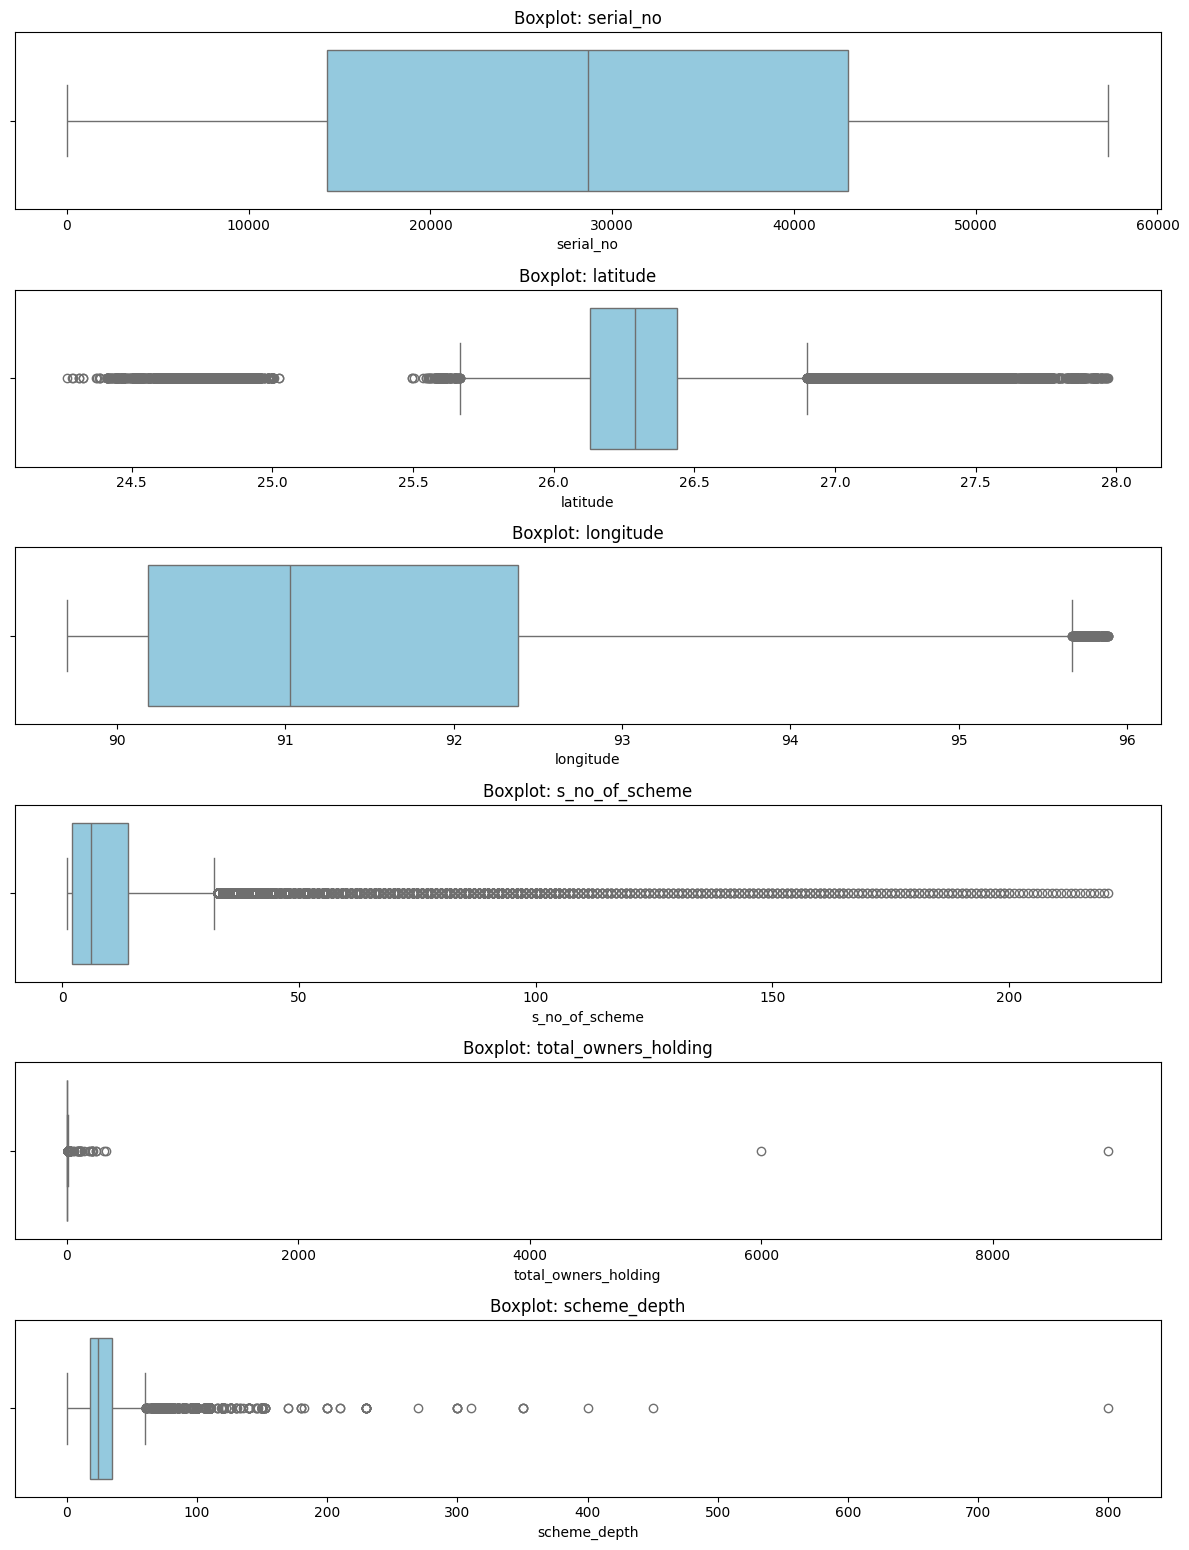

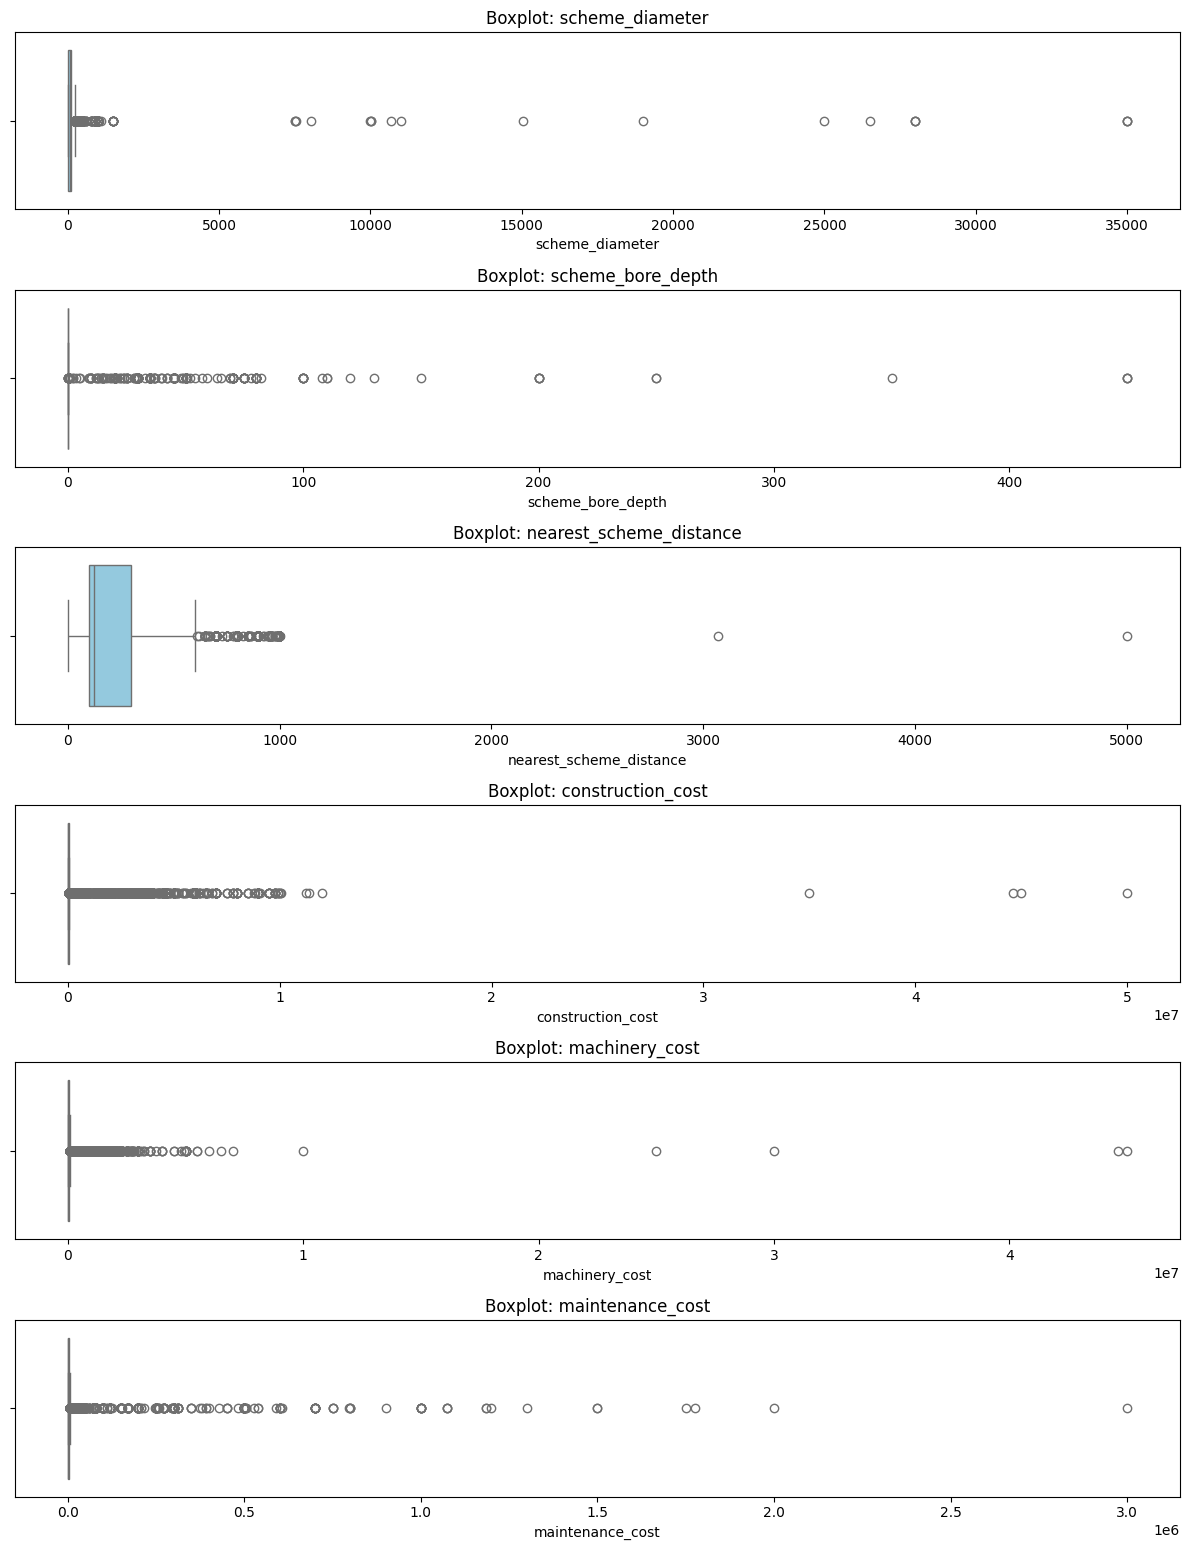

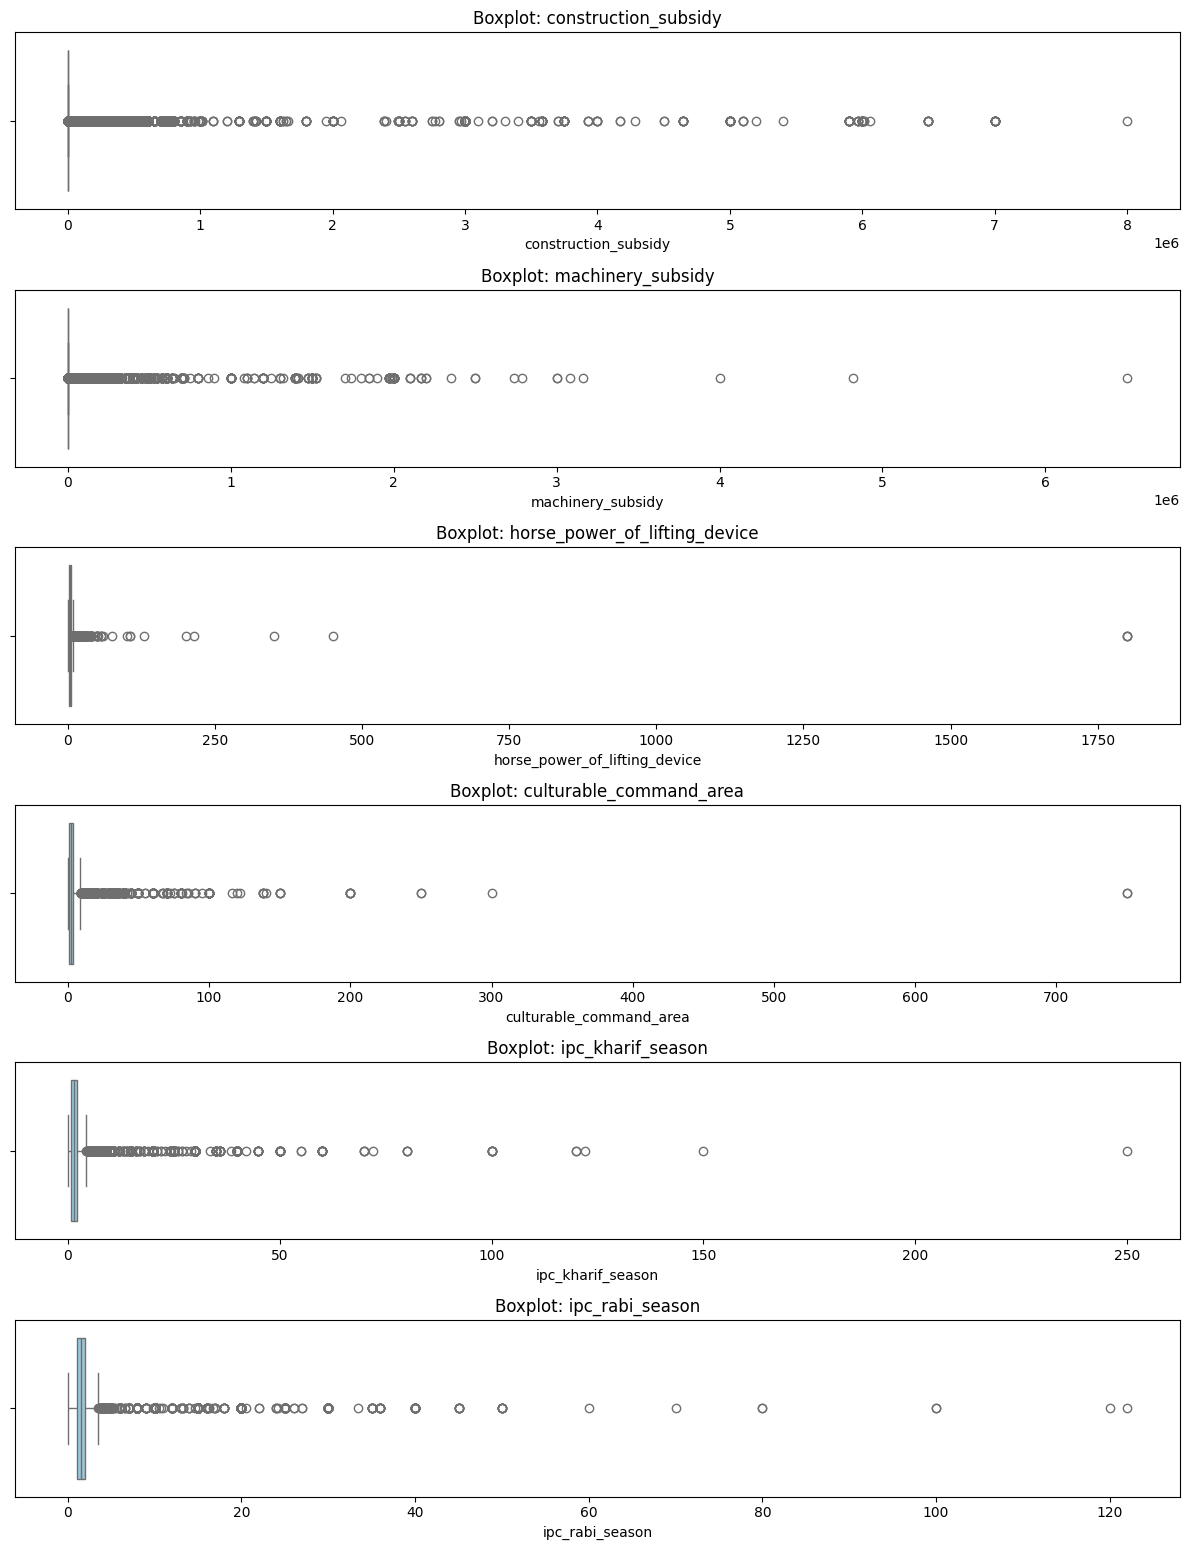

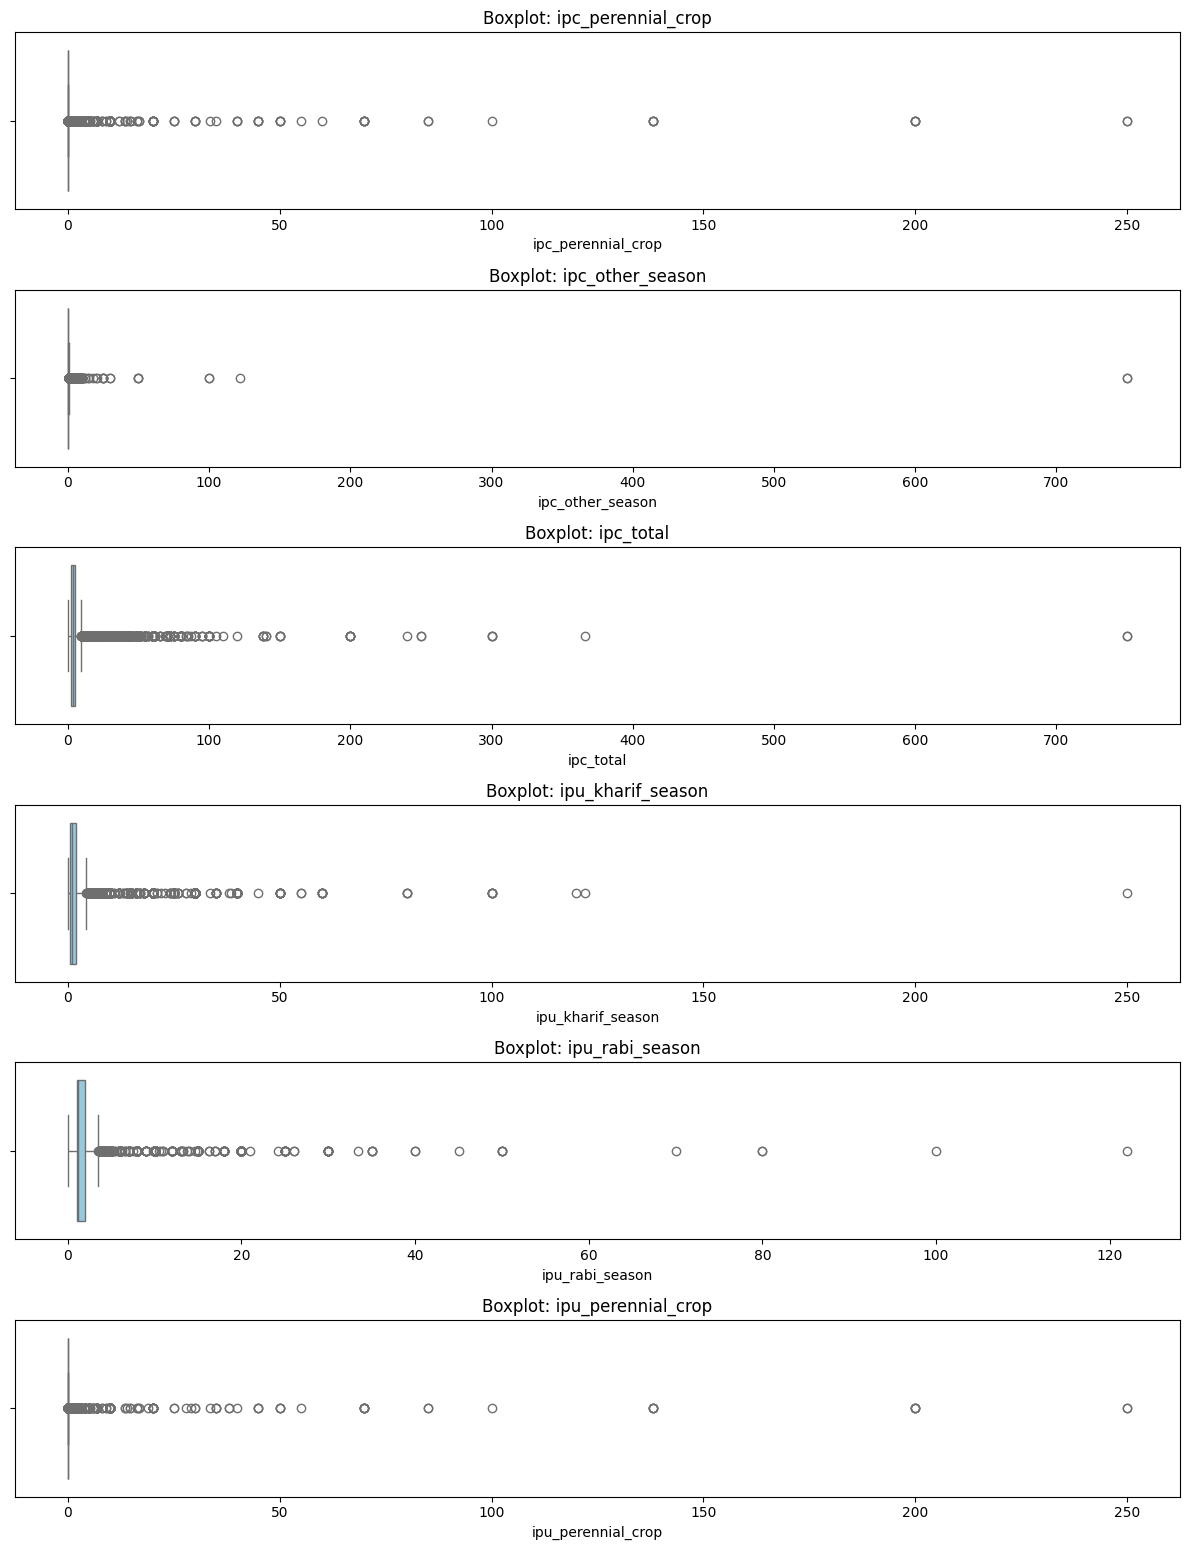

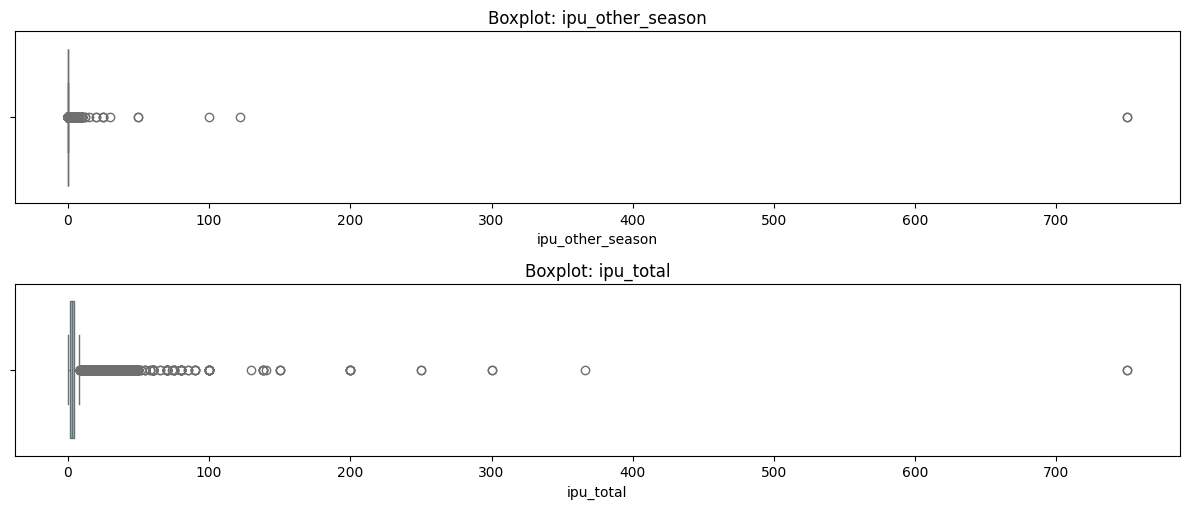

In [4]:

# Boxplots for every numeric column
cols_per_plot = 6

for start in range(0, len(numeric_cols), cols_per_plot):
    cols = numeric_cols[start:start + cols_per_plot]

    fig, axes = plt.subplots(
        nrows=len(cols), ncols=1,
        figsize=(12, 2.6 * len(cols))
    )

    if len(cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, cols):
        values = df_clean[col].dropna()

        sns.boxplot(x=values, ax=ax, color="skyblue")
        ax.set_title(f"Boxplot: {col}")
        ax.set_xlabel(col)

    plt.tight_layout()
    plt.show()


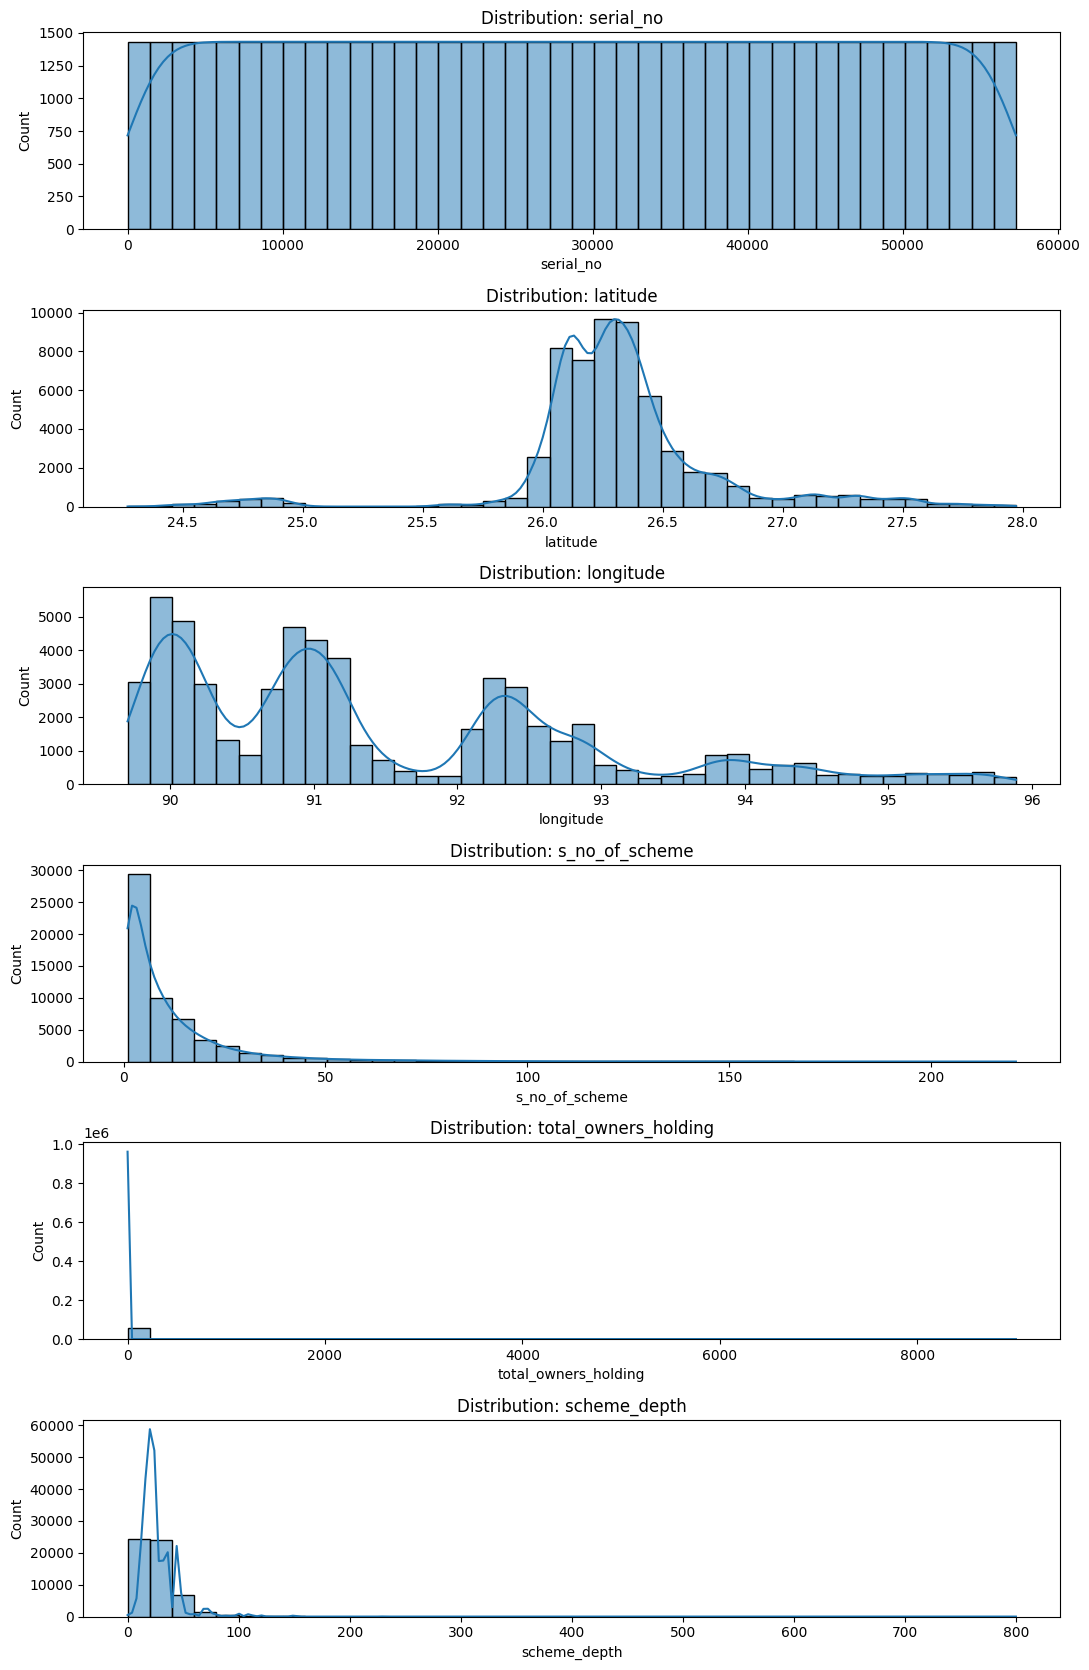

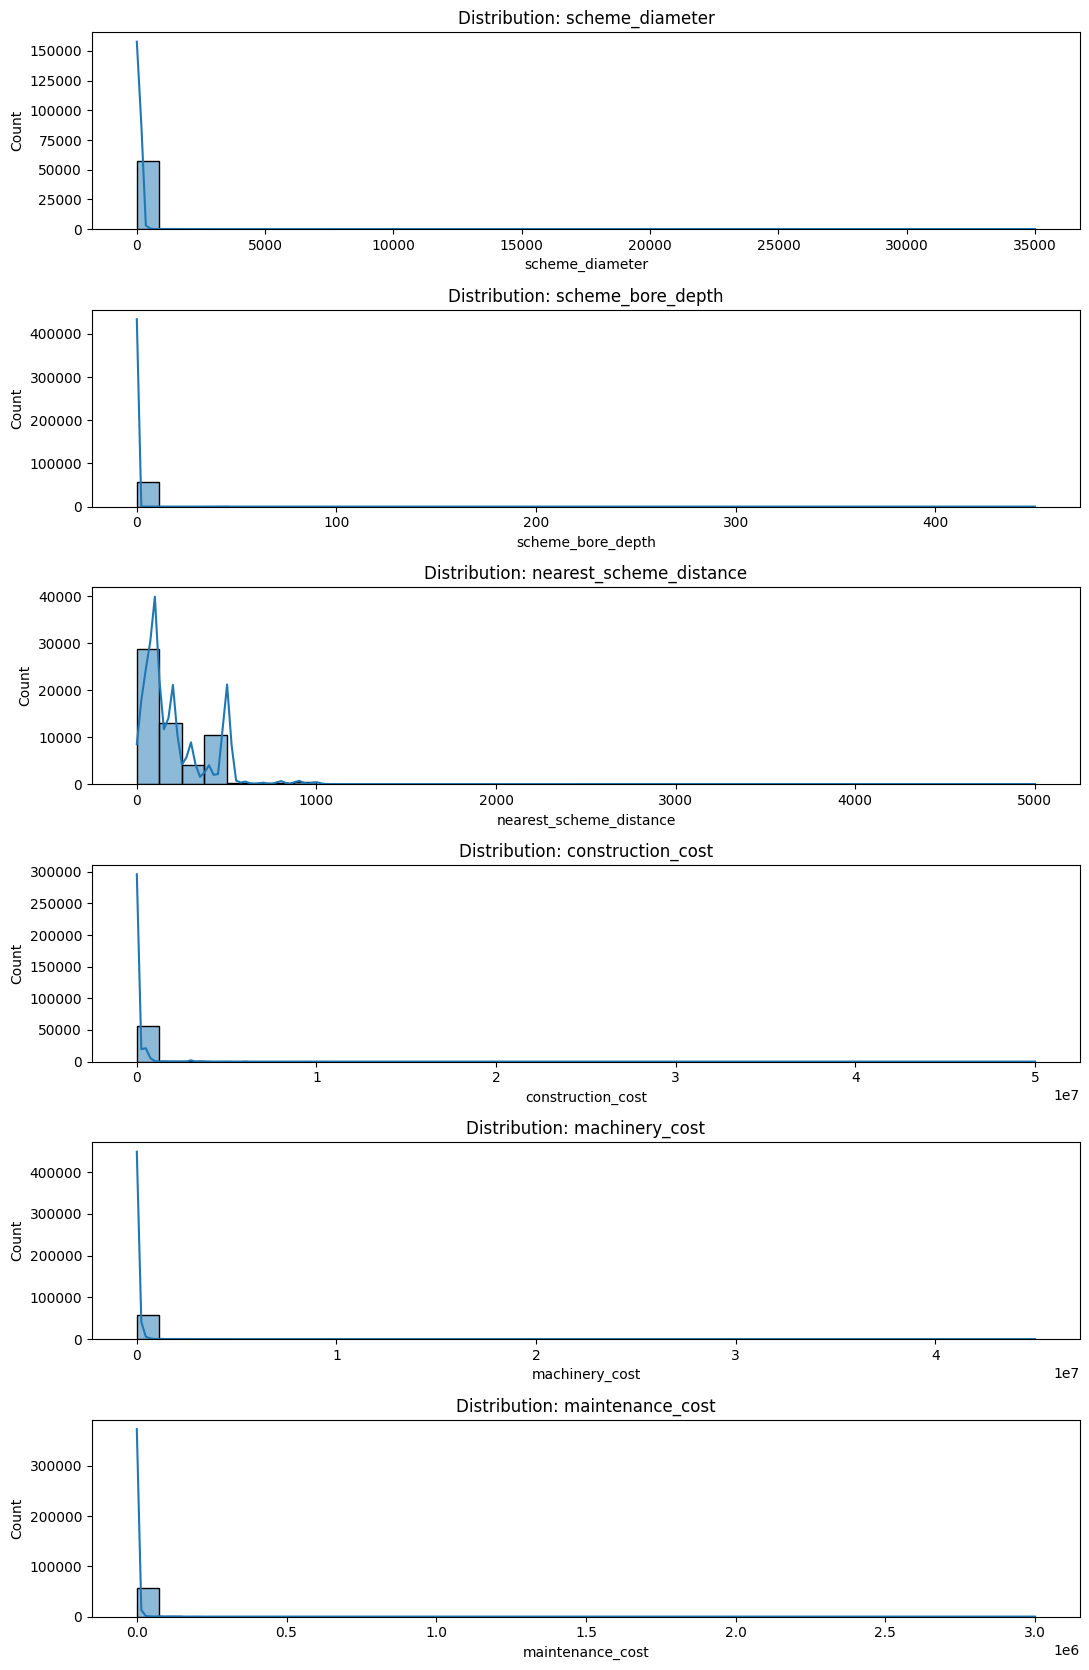

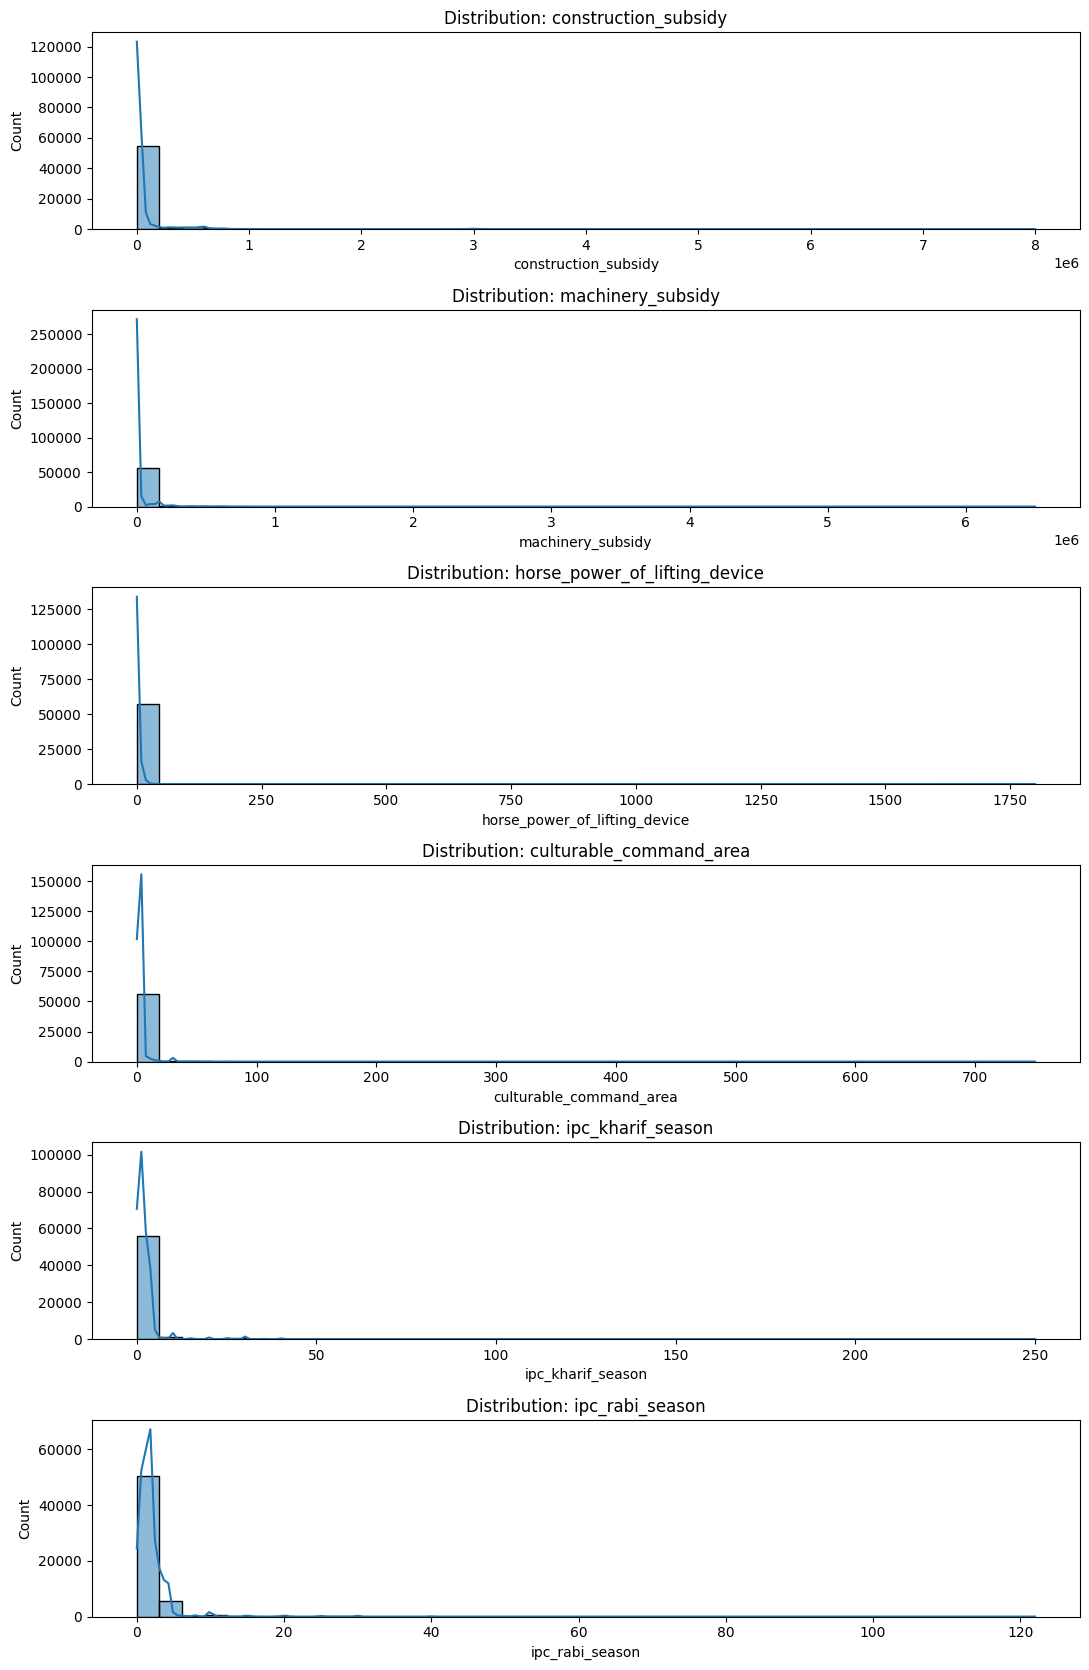

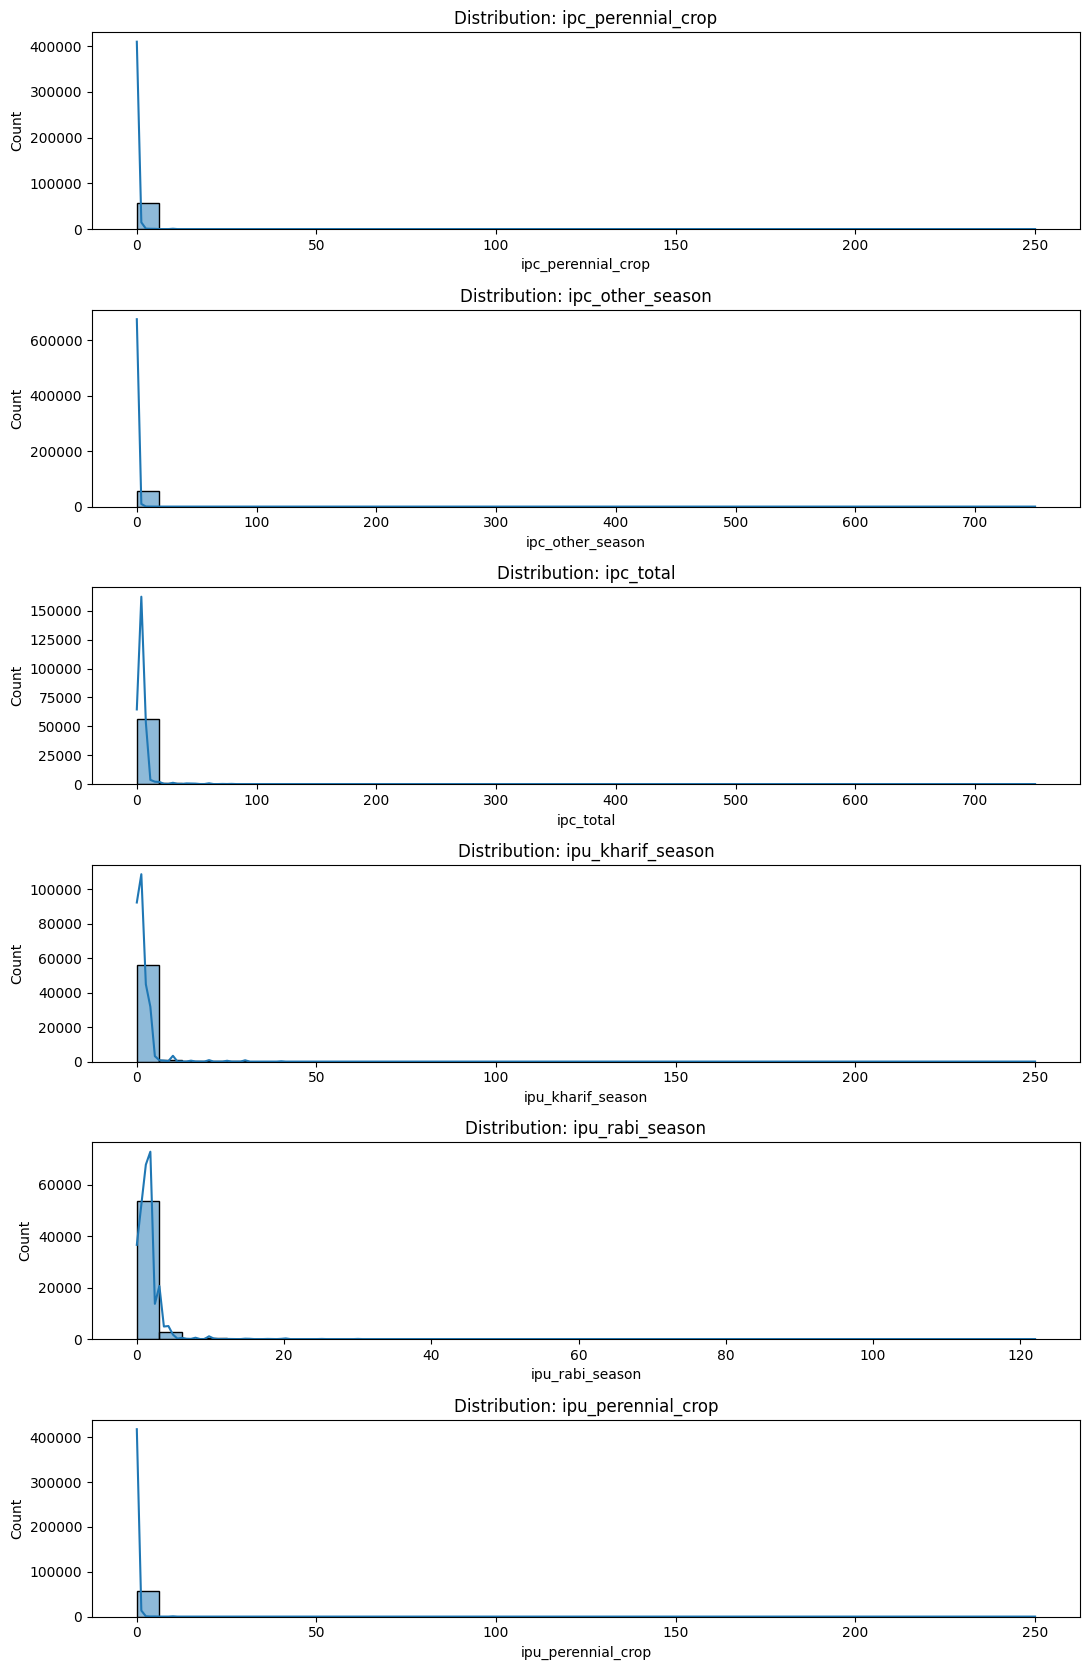

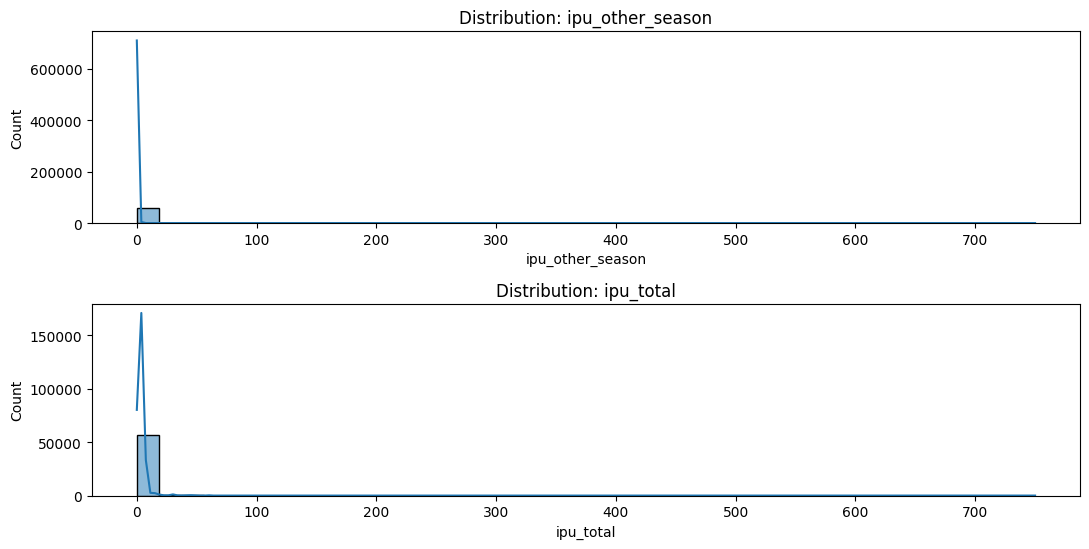

In [5]:

# Histograms for every numeric column
for start in range(0, len(numeric_cols), 6):
    cols = numeric_cols[start:start + 6]

    n = len(cols)
    fig, axes = plt.subplots(
        nrows=n, ncols=1,
        figsize=(11, 2.8 * n)
    )

    if n == 1:
        axes = [axes]

    for ax, col in zip(axes, cols):
        values = df_clean[col].dropna()

        sns.histplot(values, bins=40, kde=True, ax=ax)
        ax.set_title(f"Distribution: {col}")
        ax.set_xlabel(col)

    plt.tight_layout()
    plt.show()


In [6]:
outlier_results = []

for col in numeric_cols:
    s = df_clean[col].dropna()

    if s.empty:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (s < lower) | (s > upper)

    outlier_results.append({
        "column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percent": round(mask.mean() * 100, 2),
        "min": s.min(),
        "max": s.max()
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary = outlier_summary.sort_values(
    "outlier_percent", ascending=False
)

display(outlier_summary.round(3))


,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent,min,max
24,ipu_other_season,0.000,0.100,0.100,-0.150,0.250,12795,22.33,0.000,7.500000e+02
9,construction_cost,10000.000,35000.000,25000.000,-27500.000,72500.000,11806,20.60,0.000,5.000000e+07
19,ipc_other_season,0.000,0.200,0.200,-0.300,0.500,11190,19.53,0.000,7.500000e+02
13,machinery_subsidy,0.000,0.000,0.000,0.000,0.000,10975,19.15,0.000,6.501000e+06
10,machinery_cost,10200.000,35000.000,24800.000,-27000.000,72200.000,10648,18.58,0.000,4.500000e+07
12,construction_subsidy,0.000,0.000,0.000,0.000,0.000,10233,17.86,0.000,8.000000e+06
17,ipc_rabi_season,1.000,2.000,1.000,-0.500,3.500,6314,11.02,0.000,1.220000e+02
18,ipc_perennial_crop,0.000,0.000,0.000,0.000,0.000,6043,10.55,0.000,2.500000e+02
1,latitude,26.129,26.438,0.308,25.667,26.900,5740,10.02,24.270,2.797300e+01
23,ipu_perennial_crop,0.000,0.000,0.000,0.000,0.000,5707,9.96,0.000,2.500000e+02


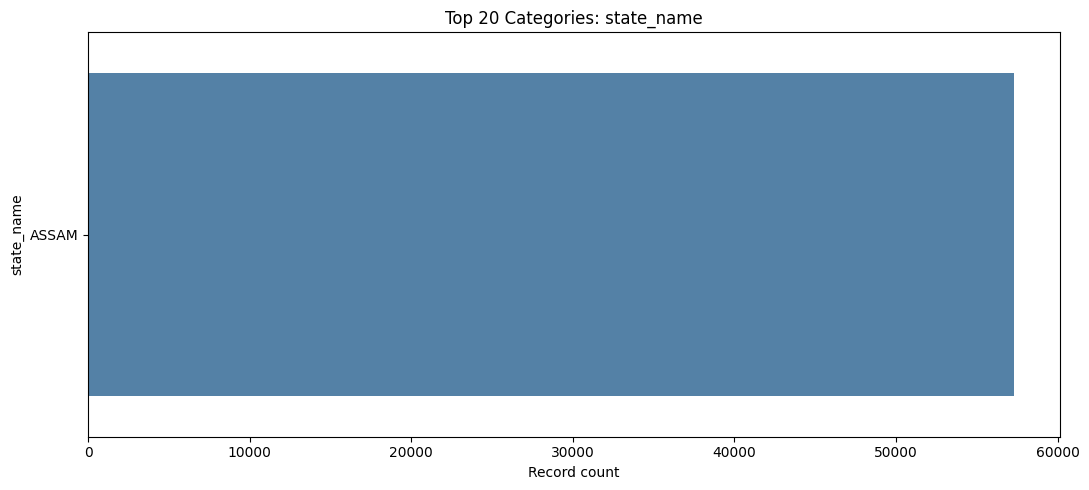

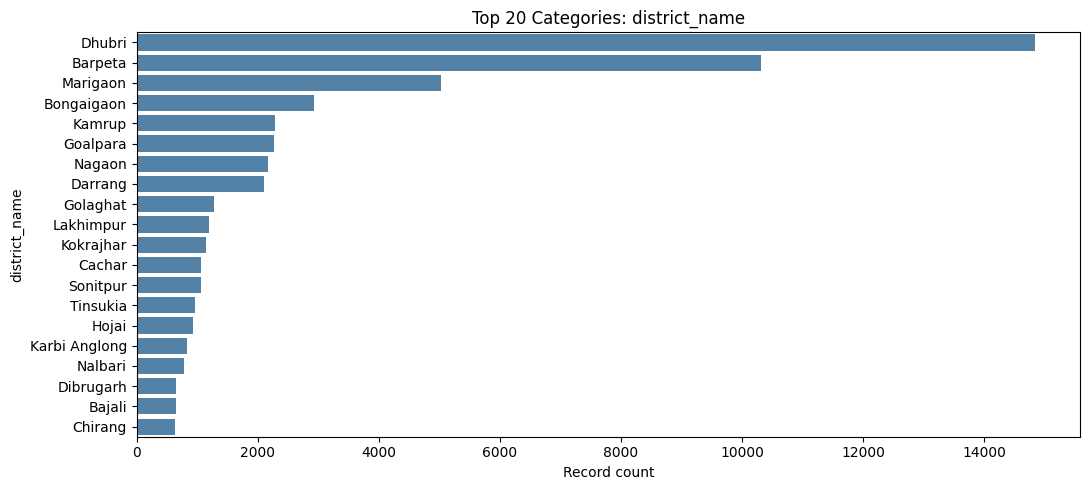

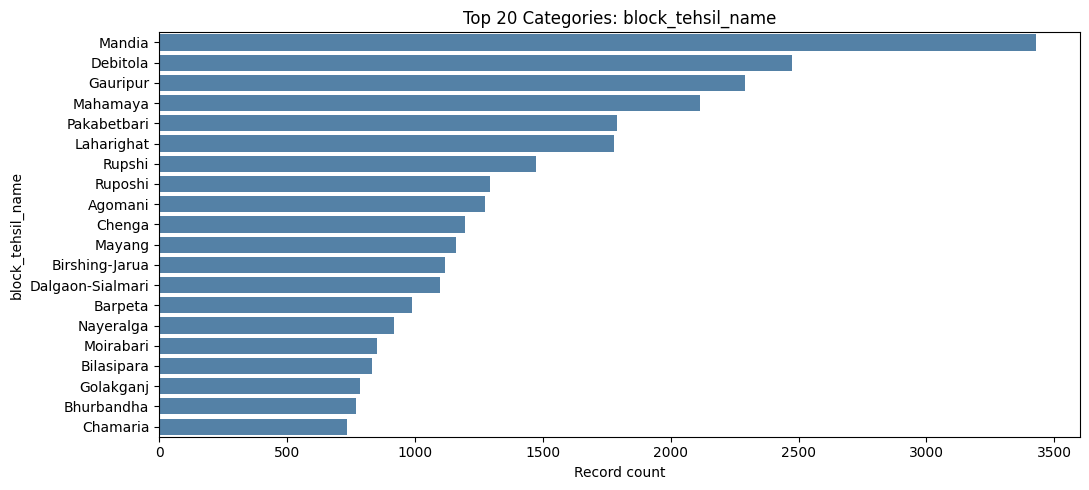

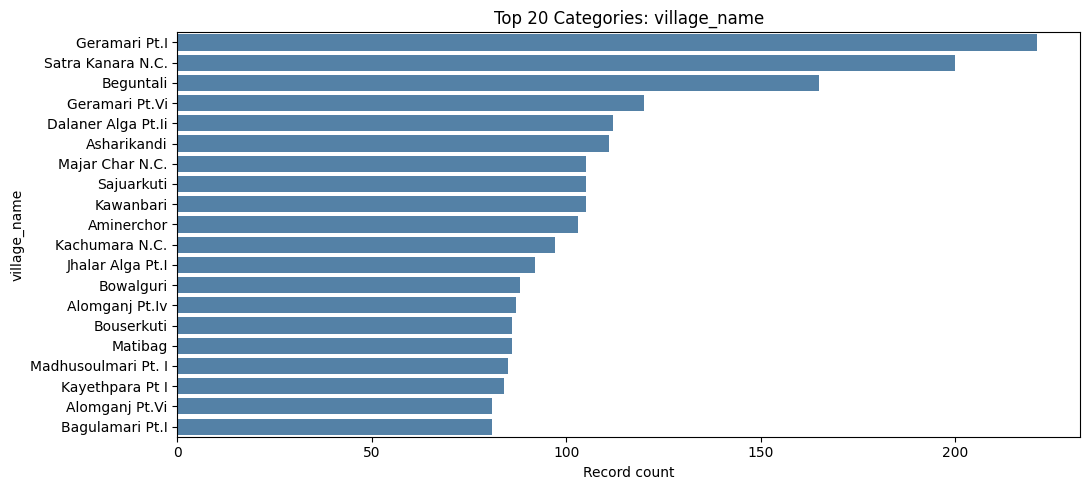

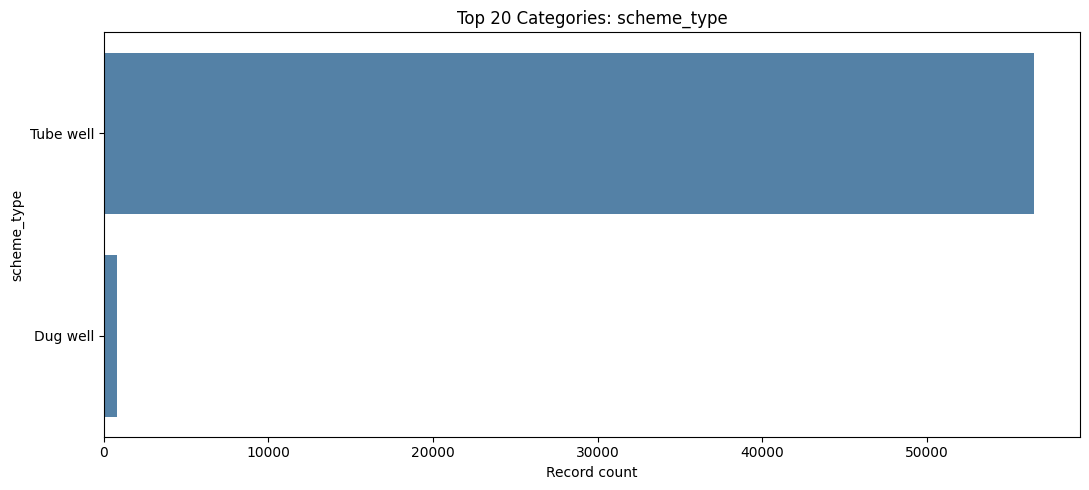

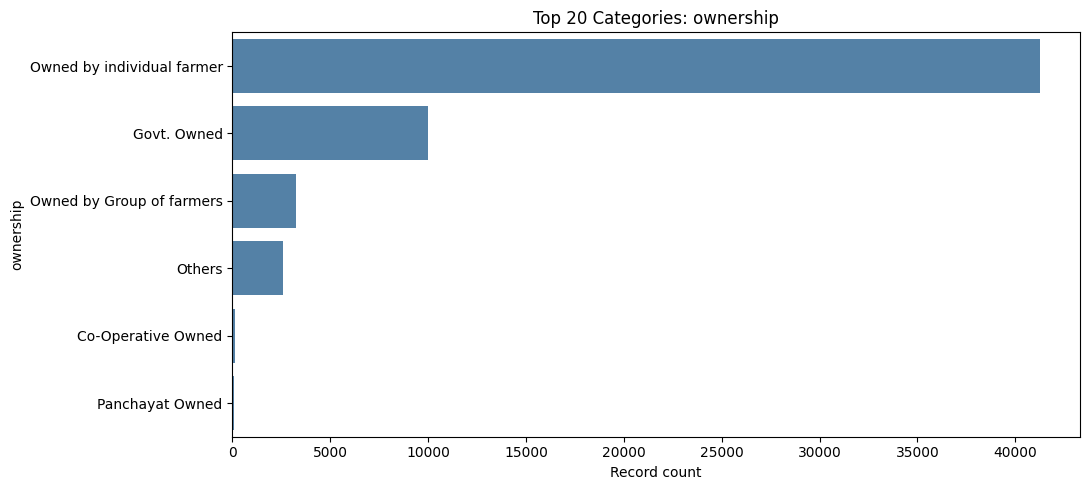

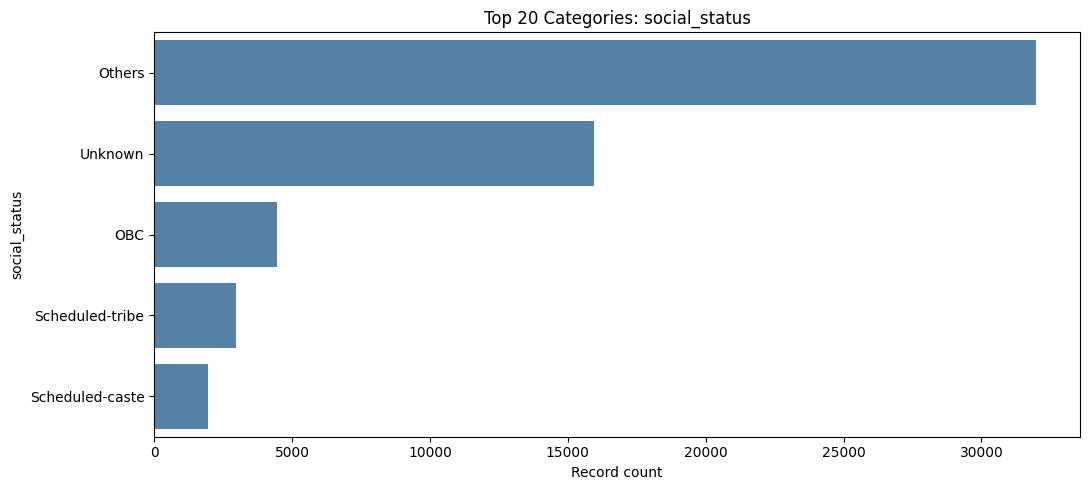

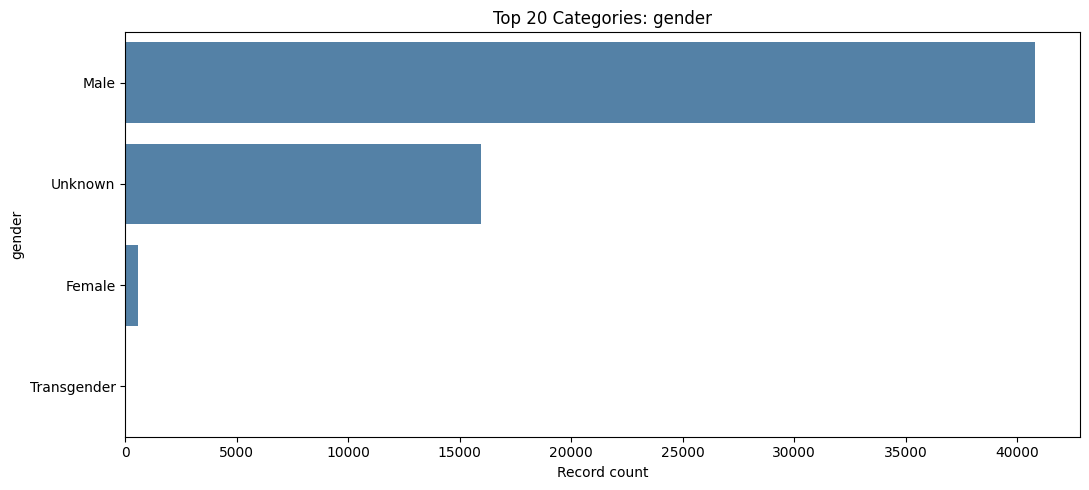

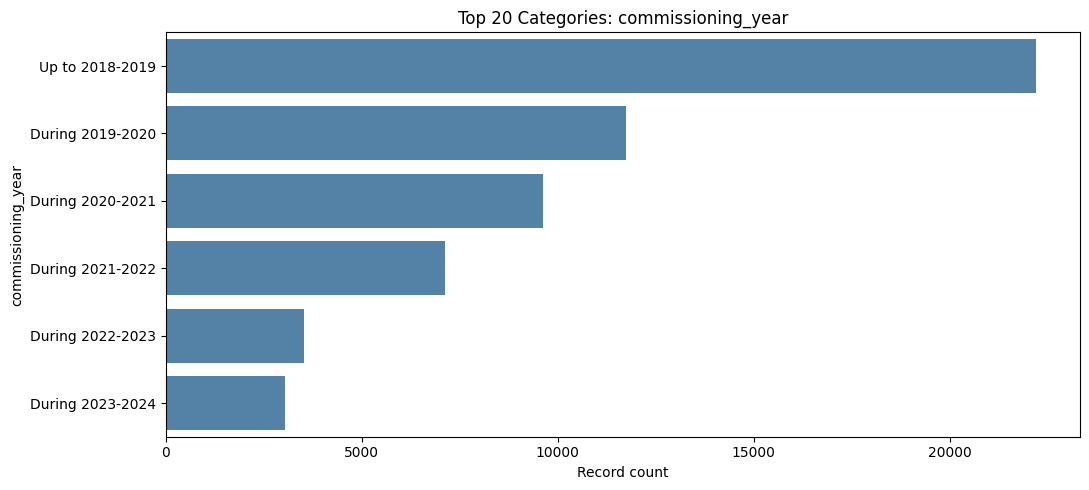

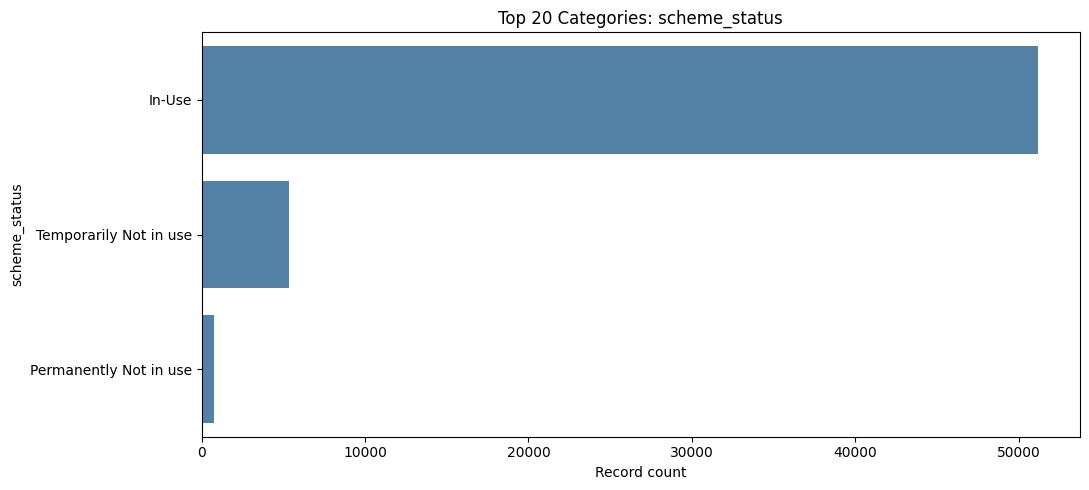

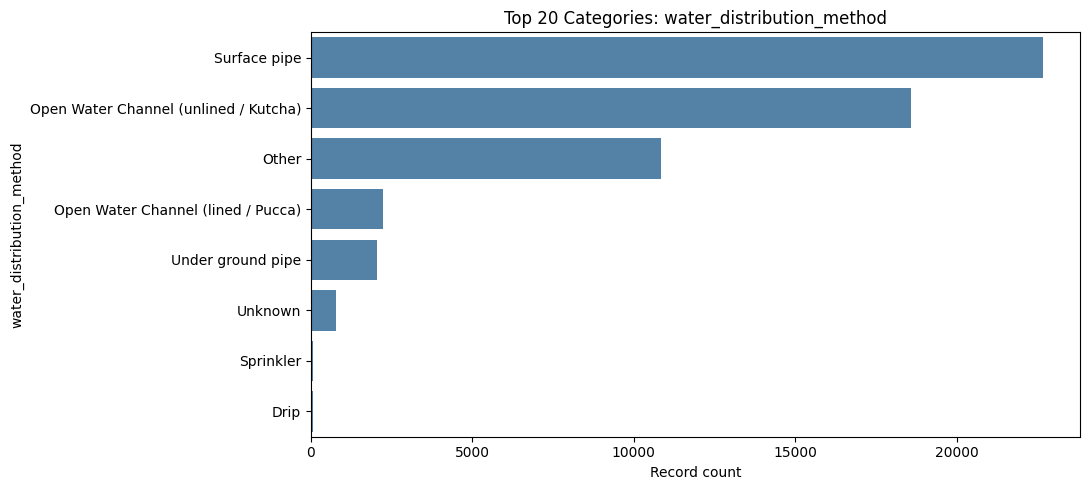

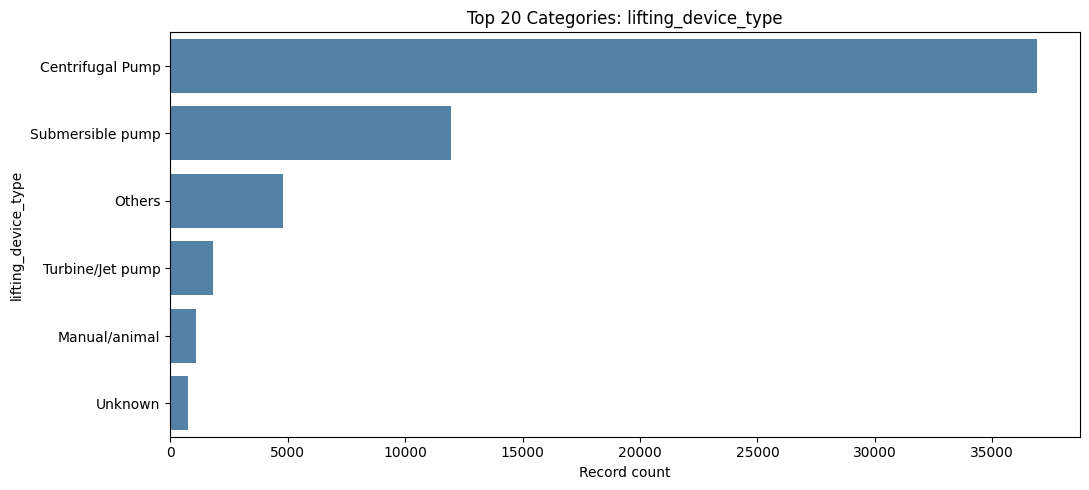

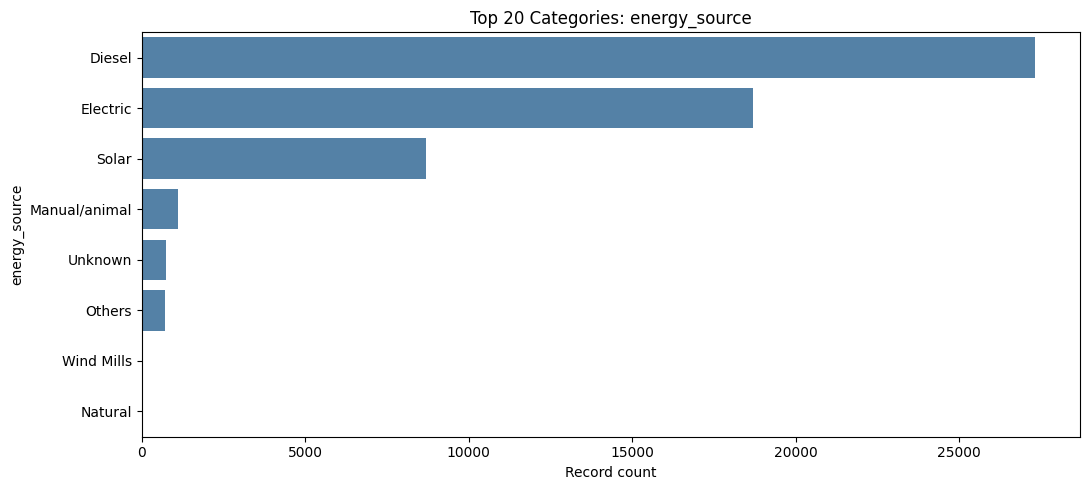

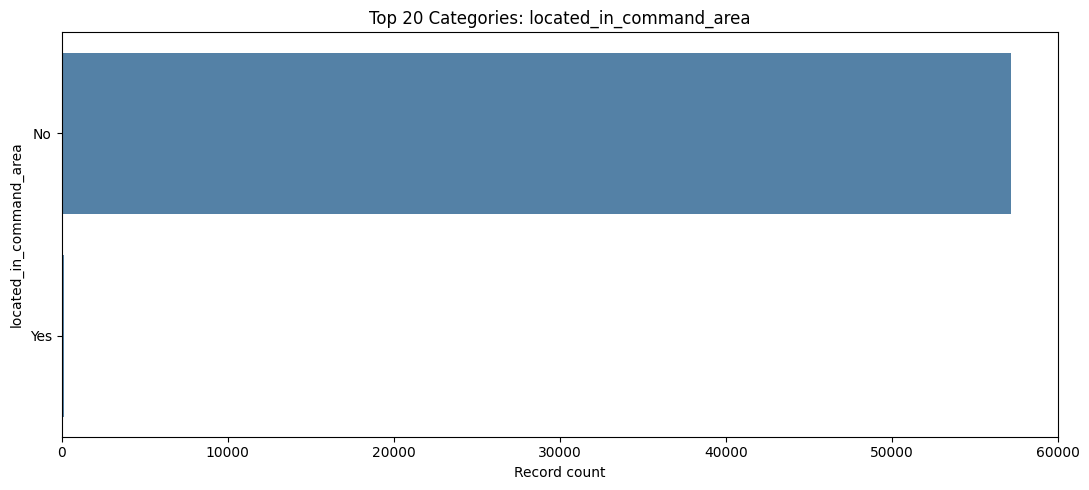

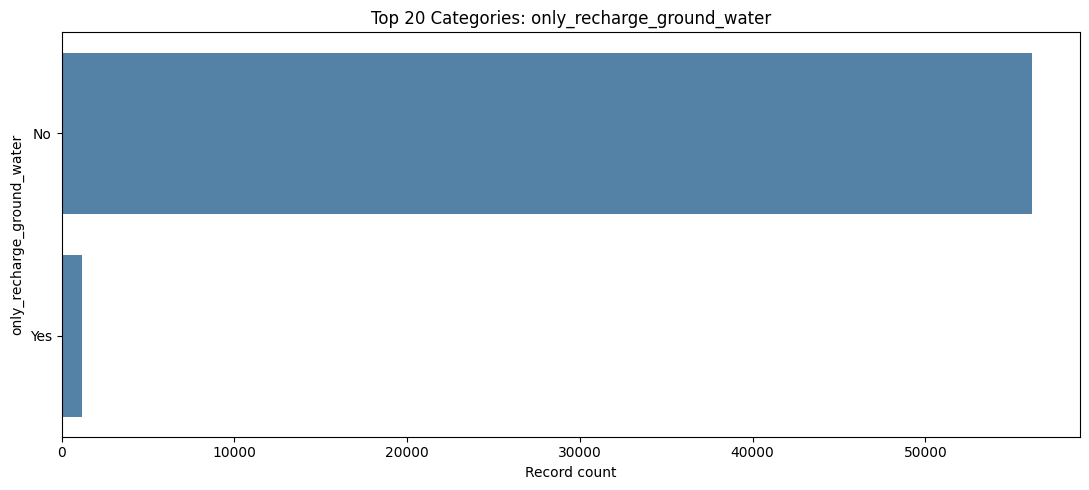

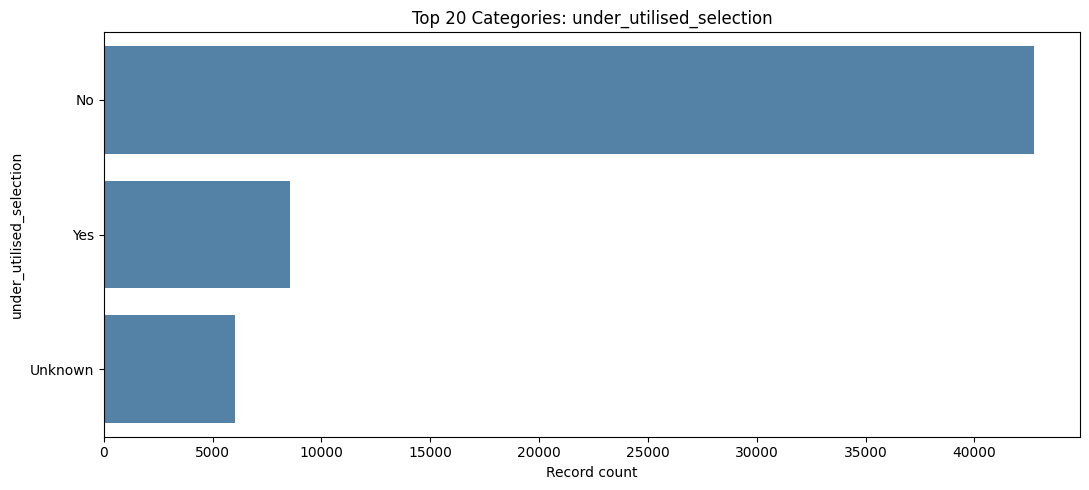

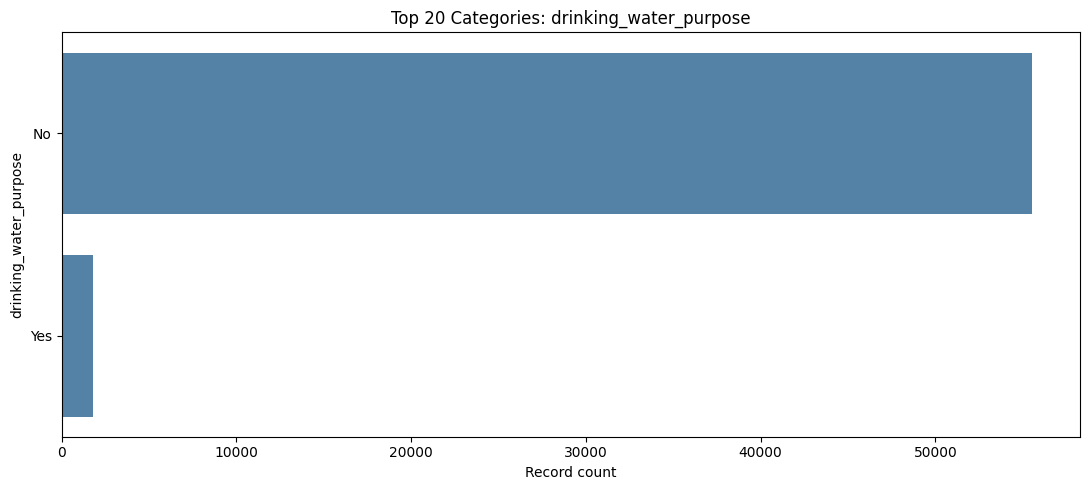

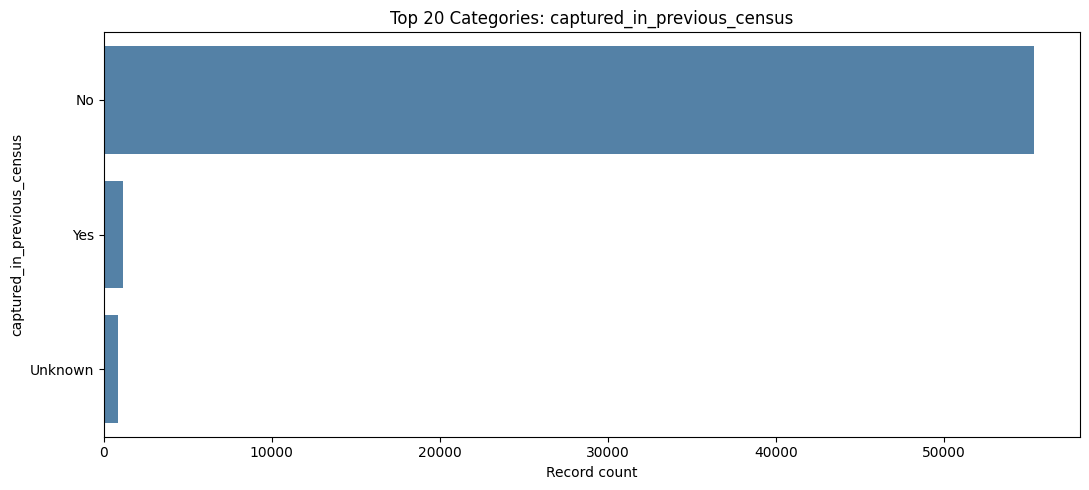

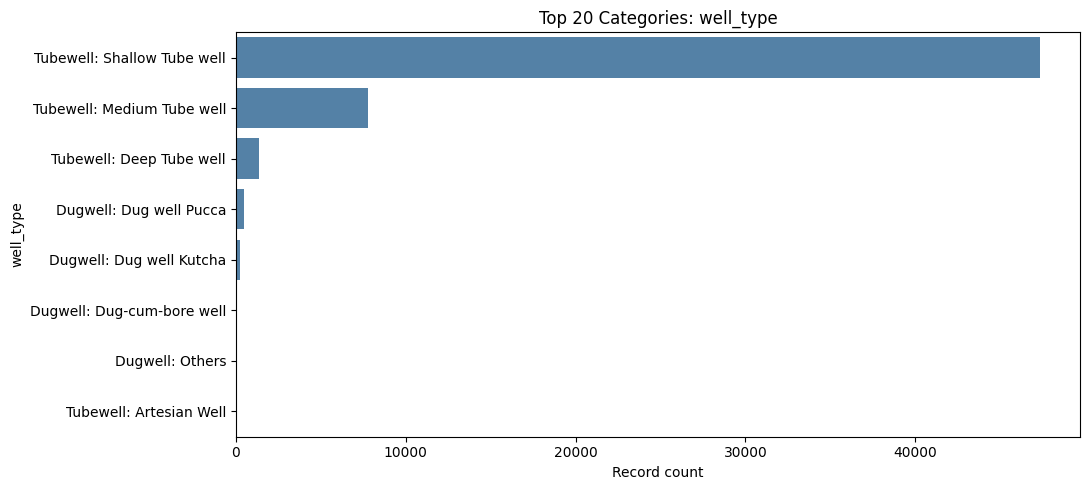

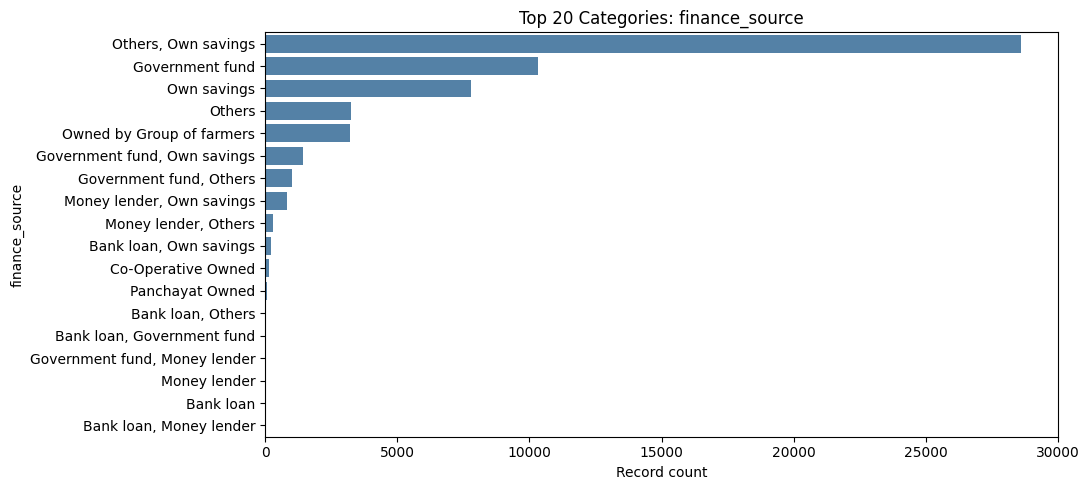

In [7]:

for start in range(0, len(categorical_cols), 4):
    cols = categorical_cols[start:start + 4]

    for col in cols:
        counts = (
            df_clean[col]
            .fillna("Missing")
            .astype(str)
            .value_counts()
        )

        # Show the 20 most common categories
        plt.figure(figsize=(11, 5))
        sns.barplot(
            x=counts.head(20).values,
            y=counts.head(20).index,
            color="steelblue"
        )
        plt.title(f"Top 20 Categories: {col}")
        plt.xlabel("Record count")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()


In [8]:

import numpy as np
import pandas as pd
from scipy.stats import zscore

# Start from the original cleaned dataset
df_model = df_clean.copy()

# 1. Drop duplicate rows
before_duplicates = len(df_model)
df_model = df_model.drop_duplicates().copy()
duplicates_removed = before_duplicates - len(df_model)

# 2. Columns excluded from outlier detection
protected_cols = {
    "construction_cost",
    "latitude",
    "longitude",
    "scheme_depth",
    "scheme_diameter",
    "nearest_scheme_distance"
}

numeric_cols = [
    col for col in df_model.select_dtypes(include="number").columns
    if col not in protected_cols
]

# 3. Detect outlier rows using IQR OR Z-score
outlier_rows = pd.Series(False, index=df_model.index)
summary = []

for col in numeric_cols:
    values = df_model[col]
    non_missing = values.dropna()

    if len(non_missing) < 2 or non_missing.nunique() <= 1:
        continue

    # IQR method
    q1 = non_missing.quantile(0.25)
    q3 = non_missing.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_flag = (values < lower) | (values > upper)
    iqr_flag = iqr_flag.fillna(False)

    # Z-score method
    z_values = pd.Series(
        np.abs(zscore(non_missing)),
        index=non_missing.index
    )

    z_flag = pd.Series(False, index=df_model.index)
    z_flag.loc[non_missing.index] = z_values > 3

    # Flag rows detected by either method
    combined_flag = iqr_flag | z_flag

    outlier_rows |= combined_flag

    summary.append({
        "column": col,
        "IQR_outliers": int(iqr_flag.sum()),
        "Zscore_outliers": int(z_flag.sum()),
        "Either_method": int(combined_flag.sum())
    })

# 4. Drop rows flagged in any eligible numeric column
rows_before = len(df_model)
df_model = df_model.loc[~outlier_rows].copy()
rows_removed = rows_before - len(df_model)

# 5. Results
print("Duplicate rows removed:", duplicates_removed)
print("Outlier rows removed:", rows_removed)
print("Final rows:", len(df_model))
print("Final columns:", len(df_model.columns))

display(
    pd.DataFrame(summary).sort_values(
        "Either_method", ascending=False
    )
)


Duplicate rows removed: 0
Outlier rows removed: 35997
Final rows: 21306
Final columns: 46


,column,IQR_outliers,Zscore_outliers,Either_method
18,ipu_other_season,12795,13,12795
13,ipc_other_season,11190,18,11190
7,machinery_subsidy,10975,590,10975
4,machinery_cost,10648,372,10648
6,construction_subsidy,10233,361,10233
11,ipc_rabi_season,6314,514,6314
12,ipc_perennial_crop,6043,162,6043
17,ipu_perennial_crop,5707,145,5707
5,maintenance_cost,4672,272,4672
1,s_no_of_scheme,4384,1183,4384


In [9]:
df.to_csv("outiars1.csv", index=False)

In [10]:

col = "total_owners_holding"

print("Data type:", df_clean[col].dtype)
print("Missing values:", df_clean[col].isna().sum())
print("Unique values:", df_clean[col].nunique())
print("\nDescriptive statistics:")
display(df_clean[col].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nMost frequent values:")
display(df_clean[col].value_counts().head(15))


Data type: float64
Missing values: 0
Unique values: 305

Descriptive statistics:


count    57303.000000
mean         1.557596
std         45.359578
min          0.000000
1%           0.000000
5%           0.000000
25%          0.000000
50%          1.000000
75%          2.000000
90%          2.660000
95%          4.000000
99%          6.000000
max       9000.000000
Name: total_owners_holding, dtype: float64


Most frequent values:


total_owners_holding
1.00    16425
0.00    16061
2.00     9209
3.00     2053
1.50     1697
4.00     1616
0.50     1018
5.00      967
0.80      551
1.33      438
0.40      434
1.20      429
0.53      414
0.66      347
6.00      341
Name: count, dtype: int64

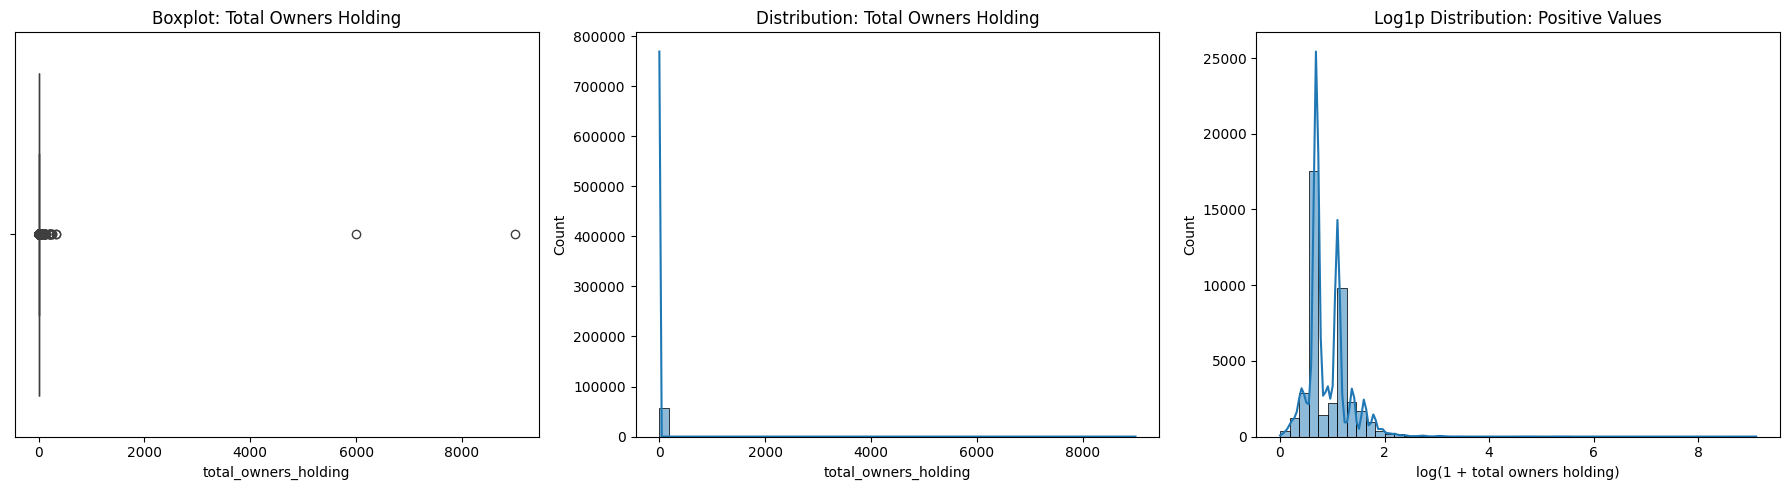

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

col = "total_owners_holding"
values = df_clean[col].dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Boxplot
sns.boxplot(x=values, ax=axes[0])
axes[0].set_title("Boxplot: Total Owners Holding")

# Histogram
sns.histplot(values, bins=50, kde=True, ax=axes[1])
axes[1].set_title("Distribution: Total Owners Holding")

# Log-scale histogram for a potentially skewed distribution
positive_values = values[values > 0]
sns.histplot(np.log1p(positive_values), bins=50, kde=True, ax=axes[2])
axes[2].set_title("Log1p Distribution: Positive Values")
axes[2].set_xlabel("log(1 + total owners holding)")

plt.tight_layout()
plt.show()


In [12]:

q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (df_clean[col] < lower_bound) |
    (df_clean[col] > upper_bound)
)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", outlier_mask.sum())
print("Outlier percentage:",
      round(outlier_mask.sum() / df_clean[col].notna().sum() * 100, 2), "%")

display(
    df_clean.loc[outlier_mask, [col]]
    .sort_values(col, ascending=False)
    .head(30)
)


Q1: 0.0
Q3: 2.0
IQR: 2.0
Lower bound: -3.0
Upper bound: 5.0
Potential outliers: 851
Outlier percentage: 1.49 %


,total_owners_holding
56735,9000.0
56736,6000.0
34200,335.0
45722,322.0
23340,250.0
7979,250.0
15247,224.0
40442,220.0
12026,220.0
12023,220.0


In [13]:

context_cols = [
    "district_name",
    "block_tehsil_name",
    "village_name",
    "ownership",
    "scheme_type",
    "well_type",
    "total_owners_holding",
    "construction_cost"
]

context_cols = [c for c in context_cols if c in df_clean.columns]

display(
    df_clean.nlargest(50, "total_owners_holding")[context_cols]
)


,district_name,block_tehsil_name,village_name,ownership,scheme_type,well_type,total_owners_holding,construction_cost
56735,Dhubri,Birshing-Jarua,Salmara Pt. VIII,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,9000.00,6500.0
56736,Dhubri,Birshing-Jarua,Salmara Pt. VIII,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,6000.00,5000.0
34200,Darrang,Bechimari,No.1 Borgara Khuti,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,335.00,7000.0
45722,Dhubri,Agomani,Kaimari Pt.V,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,322.00,15000.0
7979,Dhubri,Chapar Salkocha,Falimari T.E.,Owned by individual farmer,Tube well,Tubewell: Deep Tube well,250.00,800000.0
23340,Dhubri,Chapar Salkocha,Falimari T.E.,Owned by individual farmer,Tube well,Tubewell: Deep Tube well,250.00,800000.0
15247,Barpeta,Mandia,Salekura,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,224.00,15000.0
11586,Dhubri,Golakganj,Uzanpetla Pt.I,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,220.00,12000.0
12023,Dhubri,Golakganj,Uzanpetla Pt.Ii,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,220.00,12000.0
12026,Dhubri,Golakganj,Uzanpetla Pt.Ii,Owned by individual farmer,Tube well,Tubewell: Shallow Tube well,220.00,12000.0
